In [73]:
import pacmap
import trimap
import umap

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.datasets import make_blobs
from sklearn.neighbors import NearestNeighbors

from plotly.subplots import make_subplots

In [34]:
haberman = pd.read_csv("haberman.csv")
haberman.columns = ["age", "op_year", "axil_nodes", "surv_status"]
haberman.head()
haberman = haberman.astype(np.float32)

haberman = haberman.dropna()

X = haberman[["age", "op_year", "axil_nodes"]]
y = haberman["surv_status"]

mam = pd.read_csv('mammoth.csv')
mam = mam.sample(n=1000, random_state=42)

## Масштабирование

In [35]:
X_original = X.select_dtypes(include=[np.number]).copy()

scalers = {
    'MinMax': MinMaxScaler(),
    'Standard': StandardScaler(),
    'Robust': RobustScaler()
}

scaled_data = {}

for name, scaler in scalers.items():
    scaled_data[name] = scaler.fit_transform(X_original)

# Построим boxplot в Plotly
fig = make_subplots(
    rows=1, cols=len(scalers)+1,
    subplot_titles=['Оригинал'] + list(scalers.keys()),
    horizontal_spacing=0.05
)

# Оригинал
for i, col in enumerate(X_original.columns):
    fig.add_trace(
        go.Box(y=X_original[col], name=col, boxpoints='outliers'),
        row=1, col=1
    )

# Масштабированные
for j, (name, data_scaled) in enumerate(scaled_data.items()):
    df_scaled = pd.DataFrame(data_scaled, columns=X_original.columns)
    for i, col in enumerate(df_scaled.columns):
        fig.add_trace(
            go.Box(y=df_scaled[col], name=col, boxpoints='outliers'),
            row=1, col=j+2
        )

fig.update_layout(
    title_text="Сравнение масштабирования (Boxplot)",
    height=600,
    width=1200,
    template='plotly_white'
)
fig.show()

## Масштабирования для mammoth

In [36]:
Mam_original = mam.select_dtypes(include=[np.number]).copy()

scalers = {
    'MinMax': MinMaxScaler(),
    'Standard': StandardScaler(),
    'Robust': RobustScaler()
}

scaled_data = {}

for name, scaler in scalers.items():
    scaled_data[name] = scaler.fit_transform(Mam_original)

# Построим boxplot в Plotly
fig = make_subplots(
    rows=1, cols=len(scalers)+1,
    subplot_titles=['Оригинал'] + list(scalers.keys()),
    horizontal_spacing=0.05
)

# Оригинал
for i, col in enumerate(Mam_original.columns):
    fig.add_trace(
        go.Box(y=Mam_original[col], name=col, boxpoints='outliers'),
        row=1, col=1
    )

# Масштабированные
for j, (name, data_scaled) in enumerate(scaled_data.items()):
    df_scaled = pd.DataFrame(data_scaled, columns=Mam_original.columns)
    for i, col in enumerate(df_scaled.columns):
        fig.add_trace(
            go.Box(y=df_scaled[col], name=col, boxpoints='outliers'),
            row=1, col=j+2
        )

fig.update_layout(
    title_text="Сравнение масштабирования (Boxplot)",
    height=600,
    width=1200,
    template='plotly_white'
)
fig.show()

## TSNE

In [37]:
tsne_configs = {
    "Параметры с лекции": {
        'n_components': 2,
        'perplexity': 30,
        'early_exaggeration': 12.0,
        'learning_rate': 200,
        'max_iter': 1000,
        'n_iter_without_progress': 300,
        'min_grad_norm': 1e-07,
        'metric': 'euclidean',
        'init': 'random',
        'verbose': 0,
        'random_state': 42
    },
    "default": {},
    "Мелкие кластеры": {
        'perplexity': 5,
        'learning_rate': 200,
        'init': 'pca',
        'random_state': 42,
        'max_iter': 1000
    },
    "Большие кластеры": {
        'perplexity': 100,
        'learning_rate': 200,
        'init': 'pca',
        'random_state': 42,
        'max_iter': 1000
    },
    "Больше плотность": {
        'perplexity': 30,
        'learning_rate': 10,
        'init': 'random',
        'random_state': 42,
        'max_iter': 1000
    },
    "Точки по краям": {
        'perplexity': 30,
        'learning_rate': 2000,
        'init': 'random',
        'random_state': 42,
        'max_iter': 1000
    },
    "Сильное отталкивание": {
        'perplexity': 30,
        'learning_rate': 200,
        'init': 'random',
        'random_state': 42,
        "early_exaggeration": 50.0,
        'max_iter': 1000
    }
}

results = {}

for name, params in tsne_configs.items():
    print(f"Запуск t-SNE: {name}")
    if params:
        tsne = TSNE(**params)
    else:
        tsne = TSNE()  # default
    X_embedded = tsne.fit_transform(X)
    results[name] = X_embedded

# === 4. Визуализация: 3x3 subplot (7 графиков) ===
fig = make_subplots(
    rows=3, cols=3,
    subplot_titles=list(tsne_configs.keys()),
    horizontal_spacing=0.05,
    vertical_spacing=0.07
)

# Координаты ячеек для 7 графиков в сетке 3x3
positions = [
    (1, 1), (1, 2), (1, 3),
    (2, 1), (2, 2), (2, 3),
    (3, 1), (3, 2)  # 7-й график — в (3,2); (3,3) останется пустым
]

# Добавляем графики
for idx, (name, X_embedded) in enumerate(results.items()):
    row, col = positions[idx]
    fig.add_trace(
        go.Scatter(
            x=X_embedded[:, 0],
            y=X_embedded[:, 1],
            mode='markers',
            marker=dict(size=3, opacity=0.7),
            showlegend=False
        ),
        row=row, col=col
    )

# Настройка внешнего вида
fig.update_layout(
    title_text="TSNE: Сравнение различных параметров",
    title_x=0.5,
    height=900,
    width=1000,
    showlegend=False
)
# Убираем оси для чистоты
for i in range(1, 4):
    for j in range(1, 4):
        fig.update_xaxes(showticklabels=False, row=i, col=j)
        fig.update_yaxes(showticklabels=False, row=i, col=j)


fig.show()

Запуск t-SNE: Параметры с лекции
Запуск t-SNE: default
Запуск t-SNE: Мелкие кластеры
Запуск t-SNE: Большие кластеры
Запуск t-SNE: Больше плотность
Запуск t-SNE: Точки по краям
Запуск t-SNE: Сильное отталкивание


## UMAP

In [38]:
umap_configs = {
    "Standard": {
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "euclidean"
    },
    "High Clustering": {
        "n_neighbors": 5,
        "min_dist": 0.01,
        "metric": "euclidean"
    },
    "Global Structure": {
        "n_neighbors": 50,
        "min_dist": 0.5,
        "metric": "euclidean"
    },
    "Cosine Metric": {
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "cosine"
    },
    "Sparse Layout": {
        "n_neighbors": 30,
        "min_dist": 0.9,
        "metric": "euclidean"
    },
    "Dense Clusters": {
        "n_neighbors": 10,
        "min_dist": 0.001,
        "metric": "euclidean"
    },
    "Balanced": {
        "n_neighbors": 25,
        "min_dist": 0.2,
        "metric": "euclidean"
    }
}

# 4. Применение UMAP к каждому набору параметров
umap_results = {}
for name1, params in umap_configs.items():
    print(f"Running UMAP: {name1}")
    reducer = umap.UMAP(n_components=2, **params)
    embedding = reducer.fit_transform(X)
    umap_results[name1] = embedding

# 5. Визуализация: 7 графиков в сетке 3x3 (оставим 2 места пустыми)
fig = make_subplots(
    rows=3, cols=3,
    subplot_titles=list(umap_configs.keys()),
    horizontal_spacing=0.05,
    vertical_spacing=0.07
)

# Индексы для размещения графиков
positions = [(1,1), (1,2), (1,3),
             (2,1), (2,2), (2,3),
             (3,1), (3,2), (3,3)]

for idx, (name1, embedding) in enumerate(umap_results.items()):
    row, col = positions[idx]
    fig.add_trace(
        go.Scatter(
            x=embedding[:, 0],
            y=embedding[:, 1],
            mode='markers',
            marker=dict(size=3, opacity=0.7),
            showlegend=False
        ),
        row=row, col=col
    )

# Настройка внешнего вида
fig.update_layout(
    title_text="UMAP: Сравнение различных параметров",
    title_x=0.5,
    height=900,
    width=1000,
    showlegend=False
)

# Убрать подписи осей для чистоты
for i in range(1, 10):
    fig.update_xaxes(showticklabels=False, row=(i-1)//3 + 1, col=(i-1)%3 + 1)
    fig.update_yaxes(showticklabels=False, row=(i-1)//3 + 1, col=(i-1)%3 + 1)

# Показать график
fig.show()

Running UMAP: Standard
Running UMAP: High Clustering
Running UMAP: Global Structure
Running UMAP: Cosine Metric
Running UMAP: Sparse Layout
Running UMAP: Dense Clusters
Running UMAP: Balanced


## Trimap

In [39]:
trix = X.values.astype(np.float32)
trimap_configs = {
    "default": {},  # стандартные настройки
    "high_neighbors": {"n_inliers": 15, "n_outliers": 10, "n_random": 5},
    "low_neighbors": {"n_inliers": 5, "n_outliers": 3, "n_random": 2},
    "high_weight": {"weight_temp": 1000.0},
    "low_weight": {"weight_temp": 10.0},
    "dense_triplets": {"n_inliers": 20, "n_outliers": 15, "n_random": 10, "weight_temp": 500.0},
    "sparse_triplets": {"n_inliers": 3, "n_outliers": 2, "n_random": 1, "weight_temp": 50.0}
}

# 2. Применяем TRIMAP для каждого набора параметров
tri_results = {}
for name2, params2 in trimap_configs.items():
    print(f"Running TRIMAP with config: {name2}")
    reducer2 = trimap.TRIMAP(**params2, verbose=False)
    embedding2 = reducer2.fit_transform(trix)
    tri_results[name2] = embedding2

# 3. Создаём 7 субплотов с помощью Plotly
fig = make_subplots(
    rows=3, cols=3,
    subplot_titles=list(trimap_configs.keys()),
    horizontal_spacing=0.05,
    vertical_spacing=0.07
)

# Индексы для размещения графиков в сетке 3x3 (оставим 2 пустых)
positions = [(1,1), (1,2), (1,3),
             (2,1), (2,2), (2,3),
             (3,1), (3,2), (3,3)]

for idx, (name2, embedding2) in enumerate(tri_results.items()):
    row, col = positions[idx]
    fig.add_trace(
        go.Scatter(
            x=embedding[:, 0],
            y=embedding[:, 1],
            mode='markers',
            marker=dict(size=3, opacity=0.7),
            showlegend=False
        ),
        row=row, col=col
    )

# Убираем лишние оси и настраиваем размер
for i in range(1, 10):
    fig.update_xaxes(showticklabels=False, row=(i-1)//3 + 1, col=(i-1)%3 + 1)
    fig.update_yaxes(showticklabels=False, row=(i-1)//3 + 1, col=(i-1)%3 + 1)

fig.update_layout(
    title_text="Trimap: Сравнение различных параметров",
    title_x=0.5,
    height=900,
    width=1000,
    showlegend=False
)

fig.show()

Running TRIMAP with config: default
Running TRIMAP with config: high_neighbors
Running TRIMAP with config: low_neighbors
Running TRIMAP with config: high_weight
Running TRIMAP with config: low_weight
Running TRIMAP with config: dense_triplets
Running TRIMAP with config: sparse_triplets


## PacMAP

In [40]:
base_reducer = pacmap.PaCMAP(n_components=2, random_state=42)
base_reducer

,n_components,2
,n_neighbors,10
,MN_ratio,0.5
,FP_ratio,2.0
,pair_neighbors,None
,pair_MN,None
,pair_FP,None
,distance,'euclidean'
,lr,1.0
,num_iters,"(100, ...)"
,verbose,False


In [44]:
# 1. Проверка и очистка X

X_np = X.to_numpy()

if np.isnan(X_np).any() or np.isinf(X_np).any():
    # Замена NaN и Inf на нули (простой, но иногда не лучший вариант)
    X_np = np.nan_to_num(X_np)
    print("NaN/Inf значения были заменены.")

# 2. Приведение типа данных к float
if X_np.dtype != np.float32:
    X_np = X_np.astype(np.float32)
    print(f"Тип данных приведен к {X_np.dtype}.")

In [61]:
X_np

array([[30., 62.,  3.],
       [30., 65.,  0.],
       [31., 59.,  2.],
       [31., 65.,  4.],
       [33., 58., 10.],
       [33., 60.,  0.],
       [34., 59.,  0.],
       [34., 66.,  9.],
       [34., 58., 30.],
       [34., 60.,  1.],
       [34., 61., 10.],
       [34., 67.,  7.],
       [34., 60.,  0.],
       [35., 64., 13.],
       [35., 63.,  0.],
       [36., 60.,  1.],
       [36., 69.,  0.],
       [37., 60.,  0.],
       [37., 63.,  0.],
       [37., 58.,  0.],
       [37., 59.,  6.],
       [37., 60., 15.],
       [37., 63.,  0.],
       [38., 69., 21.],
       [38., 59.,  2.],
       [38., 60.,  0.],
       [38., 60.,  0.],
       [38., 62.,  3.],
       [38., 64.,  1.],
       [38., 66.,  0.],
       [38., 66., 11.],
       [38., 60.,  1.],
       [38., 67.,  5.],
       [39., 66.,  0.],
       [39., 63.,  0.],
       [39., 67.,  0.],
       [39., 58.,  0.],
       [39., 59.,  2.],
       [39., 63.,  4.],
       [40., 58.,  2.],
       [40., 58.,  0.],
       [40., 65.

In [66]:
haberman.columns

Index(['age', 'op_year', 'axil_nodes', 'surv_status'], dtype='object')

In [69]:
df_clean = haberman.drop_duplicates(subset=['age', 'op_year', 'axil_nodes'])
X_clean = df_clean[['age', 'op_year', 'axil_nodes']].values
# Не забудь обновить y, чтобы он соответствовал X_clean по длине!
y_clean = df_clean['surv_status'].values 

print(f"Было строк: {len(haberman)}, Стало строк: {len(df_clean)}")

pacmap_configs = {
    "run_1": 2, "run_2": 5, "run_3": 10, "run_4": 20,
    "run_5": 30, "run_6": 50, "run_7": 100 # Значения должны быть < len(X_clean)
}

Было строк: 305, Стало строк: 282


In [71]:
X_clean

array([[30., 62.,  3.],
       [30., 65.,  0.],
       [31., 59.,  2.],
       [31., 65.,  4.],
       [33., 58., 10.],
       [33., 60.,  0.],
       [34., 59.,  0.],
       [34., 66.,  9.],
       [34., 58., 30.],
       [34., 60.,  1.],
       [34., 61., 10.],
       [34., 67.,  7.],
       [34., 60.,  0.],
       [35., 64., 13.],
       [35., 63.,  0.],
       [36., 60.,  1.],
       [36., 69.,  0.],
       [37., 60.,  0.],
       [37., 63.,  0.],
       [37., 58.,  0.],
       [37., 59.,  6.],
       [37., 60., 15.],
       [38., 69., 21.],
       [38., 59.,  2.],
       [38., 60.,  0.],
       [38., 62.,  3.],
       [38., 64.,  1.],
       [38., 66.,  0.],
       [38., 66., 11.],
       [38., 60.,  1.],
       [38., 67.,  5.],
       [39., 66.,  0.],
       [39., 63.,  0.],
       [39., 67.,  0.],
       [39., 58.,  0.],
       [39., 59.,  2.],
       [39., 63.,  4.],
       [40., 58.,  2.],
       [40., 58.,  0.],
       [40., 65.,  0.],
       [41., 60., 23.],
       [41., 64.

In [74]:
X_processed = X_np.astype(np.float64) + np.random.normal(0, 0.0001, X.shape)

pacmap_configs = {
    "run_1": 2,
    "run_2": 5,
    "run_3": 10,
    "run_4": 20,
    "run_5": 30,
    "run_6": 50,
    "run_7": 100
}

pac_results = {}

print(f"Размер данных: {X_processed.shape}")

for name, n_neighbors in pacmap_configs.items():
    print(f"Запуск {name} с n_neighbors={n_neighbors}...")
    
    try:
        # --- ОБХОДНОЙ ПУТЬ ---
        # Мы НЕ полагаемся на внутренний поиск соседей PaCMAP, который падает.
        # Мы инициализируем PaCMAP с выключенным поиском (через параметр distance,
        # хотя напрямую 'precomputed' он не принимает, мы просто инициализируем объект).
        
        embedder = pacmap.PaCMAP(
            n_components=2,
            n_neighbors=n_neighbors,
            MN_ratio=0.5,
            FP_ratio=2.0,
            random_state=0
        )
        
        # В ранних версиях это помогало, но в новой версии лучше просто попробовать
        # уменьшить количество соседей, если оно близко к размеру выборки.
        # Но если ошибка сохраняется, проблема скорее всего в версии библиотеки.
        
        # Попробуем альтернативу: Если PaCMAP падает, используем fit_transform 
        # с явным указанием init="pca", иногда это помогает стабилизировать процесс.
        embeddings = embedder.fit_transform(X_processed, init="pca")
        
        pac_results[name] = embeddings
        print(f"--> Успешно")
        
    except ValueError as e:
        print(f"--> Ошибка в {name}: {e}")
        # Если стандартный метод не работает, возможно, проблема в версии библиотеки Annoy.
        # В таком случае, попробуем очень консервативные настройки.
        print("Попытка с измененными параметрами...")
        try:
             # Иногда установка distance='angular' помогает, если euclidean сбоит на нулях
            embedder = pacmap.PaCMAP(n_neighbors=n_neighbors, distance='angular', random_state=0)
            embeddings = embedder.fit_transform(X_processed)
            pac_results[name] = embeddings
            print("--> Успешно со второй попытки")
        except Exception as e2:
             print(f"--> Все равно ошибка: {e2}")

# Проверка результатов
print(f"\nПолучено результатов: {len(pac_results)}")

# --- 4. Визуализация: 7 графиков в одном окне ---
fig = make_subplots(
    rows=3, cols=3,
    subplot_titles=list(pacmap_configs.keys()),
    horizontal_spacing=0.05,
    vertical_spacing=0.07
)

# Индексы для расположения графиков
positions = [(1,1), (1,2), (1,3),
             (2,1), (2,2), (2,3),
             (3,1), (3,2), (3,3)]

for idx, (name, embedding3) in enumerate(pac_results.items()):
    row, col = positions[idx]
    fig.add_trace(
        go.Scatter(
            x=embedding3[:, 0],
            y=embedding3[:, 1],
            mode='markers',
            marker=dict(size=4, opacity=0.7),
            showlegend=False
        ),
        row=row, col=col
    )

fig.update_layout(
    title_text="PacMAP: Сравнение различных параметров",
    title_x=0.5,
    height=900,
    width=1000,
    showlegend=False
)

for i in range(1, 8):
    fig.update_xaxes(showticklabels=False, row=positions[i-1][0], col=positions[i-1][1])
    fig.update_yaxes(showticklabels=False, row=positions[i-1][0], col=positions[i-1][1])

fig.show()

Размер данных: (305, 3)
Запуск run_1 с n_neighbors=2...
--> Ошибка в run_1: could not broadcast input array from shape (0,) into shape (52,)
Попытка с измененными параметрами...
--> Все равно ошибка: could not broadcast input array from shape (0,) into shape (52,)
Запуск run_2 с n_neighbors=5...
--> Ошибка в run_2: could not broadcast input array from shape (0,) into shape (55,)
Попытка с измененными параметрами...
--> Все равно ошибка: could not broadcast input array from shape (0,) into shape (55,)
Запуск run_3 с n_neighbors=10...
--> Ошибка в run_3: could not broadcast input array from shape (0,) into shape (60,)
Попытка с измененными параметрами...
--> Все равно ошибка: could not broadcast input array from shape (0,) into shape (60,)
Запуск run_4 с n_neighbors=20...
--> Ошибка в run_4: could not broadcast input array from shape (0,) into shape (70,)
Попытка с измененными параметрами...
--> Все равно ошибка: could not broadcast input array from shape (0,) into shape (70,)
Запуск run

## TSNE, UMAP, Trimap и PacMAP для mammoth

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



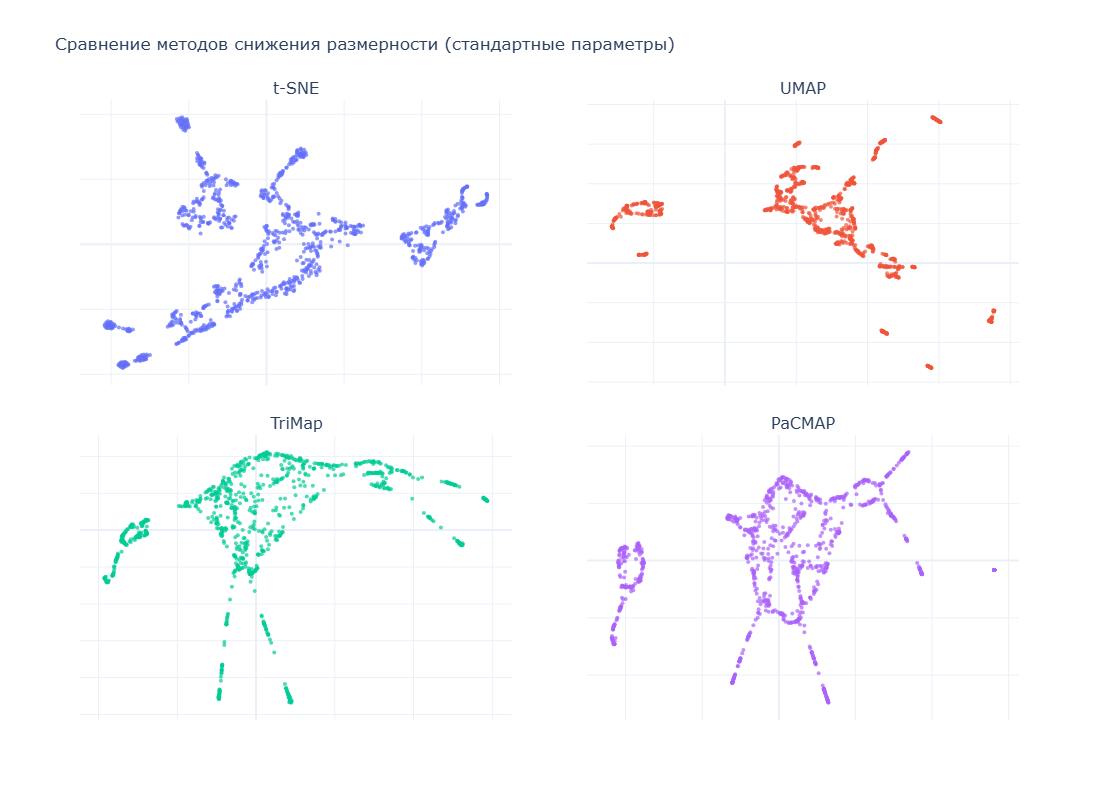

In [ ]:
mamf = mam.values.astype(np.float32)

tsnemam = TSNE(n_components=2, random_state=42)
df_tsne = tsne.fit_transform(mamf)
mamumap = umap.UMAP(n_components=2, random_state=42)
df_umap = mamumap.fit_transform(mamf)
trimapmam = trimap.TRIMAP()
df_trimap = trimapmam.fit_transform(mamf)
pacmapmam = pacmap.PaCMAP(n_components=2, random_state=42)
df_pacmap = pacmapmam.fit_transform(mamf)

mamembeddings = {
    "t-SNE": df_tsne,
    "UMAP": df_umap,
    "TriMap": df_trimap,
    "PaCMAP": df_pacmap
}

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=list(mamembeddings.keys()),
    vertical_spacing=0.08,
    horizontal_spacing=0.08
)

positions = [(1,1), (1,2), (2,1), (2,2)]

for i, (title, emb) in enumerate(mamembeddings.items()):
    r, c = positions[i]
    fig.add_trace(
        go.Scatter(
            x=emb[:, 0],
            y=emb[:, 1],
            mode='markers',
            marker=dict(size=4, opacity=0.7),
            showlegend=False
        ),
        row=r, col=c
    )

fig.update_layout(
    title_text="Сравнение методов снижения размерности (стандартные параметры)",
    height=800,
    width=900,
    template="plotly_white"
)

for r, c in positions:
    fig.update_xaxes(showticklabels=False, row=r, col=c)
    fig.update_yaxes(showticklabels=False, row=r, col=c)

fig.show()

## 3D-TSNE для mammoth

In [ ]:
mam_tsne_configs = {
    "Параметры с лекции": {
        'n_components': 3,
        'perplexity': 30,
        'early_exaggeration': 12.0,
        'learning_rate': 200,
        'max_iter': 1000,
        'n_iter_without_progress': 300,
        'min_grad_norm': 1e-07,
        'metric': 'euclidean',
        'init': 'random',
        'verbose': 0,
        'random_state': 42
    },
    "default": {
        'n_components': 3,
        'random_state': 42
    },
    "Мелкие кластеры": {
        'n_components': 3,
        'perplexity': 5,
        'learning_rate': 200,
        'init': 'pca',
        'random_state': 42,
        'max_iter': 1000
    },
    "Большие кластеры": {
        'n_components': 3,
        'perplexity': 100,
        'learning_rate': 200,
        'init': 'pca',
        'random_state': 42,
        'max_iter': 1000
    },
    "Больше плотность": {
        'n_components': 3,
        'perplexity': 30,
        'learning_rate': 10,
        'init': 'random',
        'random_state': 42,
        'max_iter': 1000
    },
    "Точки по краям": {
        'n_components': 3,
        'perplexity': 30,
        'learning_rate': 2000,
        'init': 'random',
        'random_state': 42,
        'max_iter': 1000
    },
    "Сильное отталкивание": {
        'n_components': 3,
        'perplexity': 30,
        'learning_rate': 200,
        'init': 'random',
        'random_state': 42,
        "early_exaggeration": 50.0,
        'max_iter': 1000
    }
}

mam3d_tsne_results = {}

for name3dmam, params3dmam in mam_tsne_configs.items():
    print(f"Запуск t-SNE: {name3dmam}")
    tsne = TSNE(**params3dmam)
    embedding3dmam = tsne.fit_transform(mamf)
    mam3d_tsne_results[name3dmam] = embedding3dmam

# --- 4. Визуализация: 7 графиков 3D в одном окне ---
# Plotly не поддерживает 3D-графики в make_subplots напрямую через subplot_type='scene',
# но можно создать сетку из 7 отдельных 3D-сцен.

from plotly.subplots import make_subplots

# Создаём фигуру с 7 3D-сценами
fig = make_subplots(
    rows=3, cols=3,
    specs=[
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, None, None]  # только 7 графиков
    ],
    subplot_titles=list(mam_tsne_configs.keys()),
    vertical_spacing=0.04,
    horizontal_spacing=0.02
)

# Позиции для 7 графиков
positions = [(1,1), (1,2), (1,3),
             (2,1), (2,2), (2,3),
             (3,1)]

# Добавляем каждый 3D-график
for i, (title, emb) in enumerate(mam3d_tsne_results.items()):
    row, col = positions[i]
    fig.add_trace(
        go.Scatter3d(
            x=emb[:, 0],
            y=emb[:, 1],
            z=emb[:, 2],
            mode='markers',
            marker=dict(size=3, opacity=0.8),
            showlegend=False
        ),
        row=row, col=col
    )

# Настройка макета
fig.update_layout(
    title_text="t-SNE: рсравнение различных параметров (3D)",
    title_x=0.5,
    height=1000,
    width=1200,
    template="plotly_white"
)

# Опционально: убрать подписи осей для чистоты
for i in range(1, 8):
    r, c = positions[i-1]
    fig.update_scenes(
        xaxis_visible=False,
        yaxis_visible=False,
        zaxis_visible=False,
        row=r, col=c
    )

fig.show()

Запуск t-SNE: Параметры с лекции
Запуск t-SNE: default
Запуск t-SNE: Мелкие кластеры
Запуск t-SNE: Большие кластеры
Запуск t-SNE: Больше плотность
Запуск t-SNE: Точки по краям
Запуск t-SNE: Сильное отталкивание


## 3D-UMAP для mammoth

In [ ]:
mam_umap_configs = {
    "Standard": {
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "euclidean"
    },
    "High Clustering": {
        "n_neighbors": 5,
        "min_dist": 0.01,
        "metric": "euclidean"
    },
    "Global Structure": {
        "n_neighbors": 50,
        "min_dist": 0.5,
        "metric": "euclidean"
    },
    "Cosine Metric": {
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "cosine"
    },
    "Sparse Layout": {
        "n_neighbors": 30,
        "min_dist": 0.9,
        "metric": "euclidean"
    },
    "Dense Clusters": {
        "n_neighbors": 10,
        "min_dist": 0.001,
        "metric": "euclidean"
    },
    "Balanced": {
        "n_neighbors": 25,
        "min_dist": 0.2,
        "metric": "euclidean"
    }
}

# --- Применение UMAP с 3D-вложением ---
mam_umap_results = {}

for name3dumap, params3dumap in mam_umap_configs.items():
    reducer = umap.UMAP(
        n_components=3,
        random_state=42,
        **params3dumap
    )
    embedding3dumap = reducer.fit_transform(mamf)
    mam_umap_results[name3dumap] = embedding3dumap

# Создаём подграфики 3x3, но только 7 из них используем
fig = make_subplots(
    rows=3, cols=3,
    specs=[
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, None, None]  # только 7 графиков
    ],
    subplot_titles=list(mam_umap_configs.keys()),
    vertical_spacing=0.04,
    horizontal_spacing=0.02
)

# Позиции для 7 графиков
positions = [(1,1), (1,2), (1,3),
             (2,1), (2,2), (2,3),
             (3,1)]

# Добавляем каждый 3D-график
for i, (title, emb) in enumerate(mam_umap_results.items()):
    row, col = positions[i]
    fig.add_trace(
        go.Scatter3d(
            x=emb[:, 0],
            y=emb[:, 1],
            z=emb[:, 2],
            mode='markers',
            marker=dict(size=3, opacity=0.8),
            showlegend=False
        ),
        row=row, col=col
    )

# Настройка макета
fig.update_layout(
    title_text="t-SNE: рсравнение различных параметров (3D)",
    title_x=0.5,
    height=1000,
    width=1200,
    template="plotly_white"
)

# Опционально: убрать подписи осей для чистоты
for i in range(1, 8):
    r, c = positions[i-1]
    fig.update_scenes(
        xaxis_visible=False,
        yaxis_visible=False,
        zaxis_visible=False,
        row=r, col=c
    )

fig.show()

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

C:\anaconda\Lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by se

## 3D-Trimap для mammoth

In [ ]:
mam_trimap_configs = {
    "default": {},  # стандартные настройки
    "high_neighbors": {"n_inliers": 15, "n_outliers": 10, "n_random": 5},
    "low_neighbors": {"n_inliers": 5, "n_outliers": 3, "n_random": 2},
    "high_weight": {"weight_temp": 1000.0},
    "low_weight": {"weight_temp": 10.0},
    "dense_triplets": {"n_inliers": 20, "n_outliers": 15, "n_random": 10, "weight_temp": 500.0},
    "sparse_triplets": {"n_inliers": 3, "n_outliers": 2, "n_random": 1, "weight_temp": 50.0}
}

mam_trimap_results = {}

for name3dtrim, params3dtrim in mam_trimap_configs.items():
    # Создаём reducer с n_dims=3 и вашими параметрами
    reducer = trimap.TRIMAP(
        n_dims=3,
        **params3dtrim
    )
    embedding3dtrims = reducer.fit_transform(mamf)
    mam_trimap_results[name3dtrim] = embedding3dtrims

fig = make_subplots(
    rows=3, cols=3,
    specs=[
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, None, None]  # только 7 графиков
    ],
    subplot_titles=list(mam_trimap_configs.keys()),
    vertical_spacing=0.04,
    horizontal_spacing=0.02
)

# Позиции для 7 графиков
positions = [(1,1), (1,2), (1,3),
             (2,1), (2,2), (2,3),
             (3,1)]

# Добавляем каждый 3D-график
for i, (title, emb) in enumerate(mam_trimap_results.items()):
    row, col = positions[i]
    fig.add_trace(
        go.Scatter3d(
            x=emb[:, 0],
            y=emb[:, 1],
            z=emb[:, 2],
            mode='markers',
            marker=dict(size=3, opacity=0.8),
            showlegend=False
        ),
        row=row, col=col
    )

# Настройка макета
fig.update_layout(
    title_text="t-SNE: рсравнение различных параметров (3D)",
    title_x=0.5,
    height=1000,
    width=1200,
    template="plotly_white"
)

# Опционально: убрать подписи осей для чистоты
for i in range(1, 8):
    r, c = positions[i-1]
    fig.update_scenes(
        xaxis_visible=False,
        yaxis_visible=False,
        zaxis_visible=False,
        row=r, col=c
    )

fig.show()

## 3D-PacMAP для mammoth

In [ ]:
mam_pacmap_configs = {
    "run_1": 0,
    "run_2": 1,
    "run_3": 42,
    "run_4": 100,
    "run_5": 999,
    "run_6": 1234,
    "run_7": 5678
}

mam_pacmap_results = {}

for name3dpac, random_state3d in mam_pacmap_configs.items():
    reducer = pacmap.PaCMAP(
        n_components=3,
    )
    embedding3dpac = reducer.fit_transform(mamf)
    mam_pacmap_results[name3dpac] = embedding3dpac

fig = make_subplots(
    rows=3, cols=3,
    specs=[
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, {"type": "scene"}, {"type": "scene"}],
        [{"type": "scene"}, None, None]  # только 7 графиков
    ],
    subplot_titles=list(mam_pacmap_configs.keys()),
    vertical_spacing=0.04,
    horizontal_spacing=0.02
)

positions = [(1,1), (1,2), (1,3),
             (2,1), (2,2), (2,3),
             (3,1)]

for i, (title, emb) in enumerate(mam_pacmap_results.items()):
    row, col = positions[i]
    fig.add_trace(
        go.Scatter3d(
            x=emb[:, 0],
            y=emb[:, 1],
            z=emb[:, 2],
            mode='markers',
            marker=dict(size=3, opacity=0.8),
            showlegend=False
        ),
        row=row, col=col
    )

fig.update_layout(
    title_text="t-SNE: рсравнение различных параметров (3D)",
    title_x=0.5,
    height=1000,
    width=1200,
    template="plotly_white"
)

for i in range(1, 8):
    r, c = positions[i-1]
    fig.update_scenes(
        xaxis_visible=False,
        yaxis_visible=False,
        zaxis_visible=False,
        row=r, col=c
    )

fig.show()

Note: `n_components != 2` have not been thoroughly tested.
Note: `n_components != 2` have not been thoroughly tested.
Note: `n_components != 2` have not been thoroughly tested.
Note: `n_components != 2` have not been thoroughly tested.
Note: `n_components != 2` have not been thoroughly tested.
Note: `n_components != 2` have not been thoroughly tested.
Note: `n_components != 2` have not been thoroughly tested.
